# Гибридная система рекомендаций книг на Goodbooks-10k

Итоговый проект продолжает домашнее задание (ноутбук 01_homework_baselines.ipynb). Модели домашнего задания (item-based CF на оценках и на факте прочтения, контентная модель, SVD, популярность) становятся генераторами кандидатов. Их кандидаты объединяются в общий пул, к ним добавляются признаки книг и пар пользователь–книга, итоговый скор считается взвешенной суммой с отдельными весами для новых и активных пользователей, а финальная выдача разбавляется по жанрам. Веса подбираются на валидационной выборке, качество проверяется один раз на тестовой.

## 1. Подготовка

В Colab ячейка ниже клонирует репозиторий и ставит scikit-surprise, при локальном запуске из папки notebooks её нужно пропустить. Если scikit-surprise не собирается под numpy 2, нужно поставить numpy<2 и перезапустить среду.

In [1]:
!git clone -q https://github.com/EgorCOStylev/goodbooks-hybrid-recsys.git
%cd goodbooks-hybrid-recsys
!pip install -q scikit-surprise

fatal: destination path 'goodbooks-hybrid-recsys' already exists and is not an empty directory.
/content/goodbooks-hybrid-recsys


In [2]:
import warnings
warnings.filterwarnings('ignore')

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from recsys import data, features, hybrid, metrics, pipeline
from recsys.plots import show_table

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

DATA_DIR    = Path(kagglehub.dataset_download('zygmunt/goodbooks-10k'))
SEED        = 42
THRESHOLD   = 4
K           = 10
N_PER_MODEL = 100
N_NEW       = 3000
N_TUNE      = 8000
GRID        = [-0.5, 0, 0.05, 0.1, 0.25, 0.5, 1, 2]
LAMBDAS     = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]
SEGMENTS    = {'new': 'новые', 'active': 'активные'}

Using Colab cache for faster access to the 'goodbooks-10k' dataset.


## 2. Данные

Загрузка и очистка повторяют домашнее задание: повторные пары пользователь–книга схлопываются в среднюю оценку, теги переводятся с goodreads_book_id на id из books.csv.

In [3]:
raw       = data.load_raw(DATA_DIR)
books     = raw['books']
ratings, dup_rows, conflicts = data.dedup_ratings(raw['ratings'])
books['original_title']      = books.original_title.fillna(books.title)
book_tags                    = data.attach_tags(raw['book_tags'], books, raw['tags'])

ratings.head()

,user_id,book_id,rating
0,1,1180,4.0
1,1,4893,3.0
2,1,6285,4.0
3,2,8034,4.0
4,2,8855,5.0


In [4]:
print(f'Оценок после очистки: {len(ratings):,}, пользователей: {ratings.user_id.nunique():,}, книг: {ratings.book_id.nunique():,}')
print(f'Строк в повторных парах: {dup_rows:,}, из них пар с разными оценками: {conflicts:,}')

Оценок после очистки: 979,478, пользователей: 53,424, книг: 10,000
Строк в повторных парах: 4,487, из них пар с разными оценками: 633


## 3. Обучающая, валидационная и тестовая выборки

Тестовая выборка совпадает с тестом домашнего задания: то же случайное разделение внутри пользователя с тем же seed, 20% оценок у каждого пользователя с не менее чем 5 оценками. Из оставшейся части тем же способом отрезается валидационная выборка. На валидации подбираются веса гибрида и параметр разнообразия, тестовая выборка используется один раз в разделе 10. В домашнем задании число соседей item-based CF выбиралось по тесту, здесь этого ограничения нет.

In [5]:
fit, val, test = data.split_train_val_test(ratings, seed=SEED)
_, test_hw     = data.split_per_user(ratings, seed=SEED)
idx            = data.Index(users=np.sort(ratings.user_id.unique()), books=np.sort(books.id.unique()))

fit.head()

,user_id,book_id,rating
0,1,1180,4.0
1,1,4893,3.0
2,1,6285,4.0
3,2,8034,4.0
4,2,8855,5.0


In [6]:
for name, part in (('fit', fit), ('val', val), ('test', test)):
    print(f'{name:<5} оценок: {len(part):>8,} ({len(part) / len(ratings):.1%}), пользователей: {part.user_id.nunique():,}')
same = len(test) == len(test_hw) == len(test.merge(test_hw, on=['user_id', 'book_id']))
print(f'Тестовая выборка совпадает с тестом домашнего задания: {same}')

fit   оценок:  669,366 (68.3%), пользователей: 53,424
val   оценок:  136,860 (14.0%), пользователей: 32,439
test  оценок:  173,252 (17.7%), пользователей: 35,659
Тестовая выборка совпадает с тестом домашнего задания: True


## 4. Сегмент новых пользователей

Пользователи, у которых меньше 5 оценок, целиком остаются в обучающей части и в оценке не участвуют, поэтому новых пользователей приходится моделировать. Из пользователей валидации, у которых в обучающей части не меньше 10 оценок, случайно выбираются 3000, и их история обрезается до 1, 2 или 3 книг, по 1000 человек на каждый вариант. Все модели обучаются уже на обрезанных данных, иначе SVD и сходства книг помнили бы удалённые оценки. Пользователь относится к сегменту новых, если у него в обучающей части не больше 3 книг.

In [7]:
rel_val              = metrics.relevance_matrix(val, idx, THRESHOLD)
fit_t, new_val_users = pipeline.simulate_new_users(fit, rel_val, idx, n_users=N_NEW, seed=SEED)

fit_t.groupby('user_id').size().loc[new_val_users].value_counts().sort_index().to_frame('пользователей')

,пользователей
1,1000
2,1000
3,1000


In [8]:
print(f'Оценок удалено из обучающей части: {len(fit) - len(fit_t):,} ({1 - len(fit_t) / len(fit):.1%})')

Оценок удалено из обучающей части: 75,666 (11.3%)


## 5. Генераторы кандидатов и общий пул

Каждая модель отдаёт для пользователя 100 лучших книг, которых он не читал, и кандидаты объединяются. Генераторов шесть: item-based CF на факте прочтения (cf_implicit) и на оценках (cf_explicit), контентная модель (content), SVD, популярность по ratings_count на Goodreads (known) и неперсонализированная модель домашнего задания на сглаженной средней оценке (bayes). Популярность по ratings_count добавлена потому, что в домашнем задании модель по средней оценке оказалась на уровне случайной выдачи, а новым пользователям нужна известность книги. Параметры SVD взяты из кросс-валидации домашнего задания: 50 факторов, reg_all 0,05.

Скор каждой модели в пуле заменяется на ранг: 1 у первой книги модели, 0 у книги вне её топ-100. Так скоры с разными шкалами (прогноз оценки, косинус, сумма сходств) можно складывать.

Recall пула показывает долю релевантных книг пользователя, попавших в пул. Это потолок для любого ранжирования на втором этапе: книгу, которой нет в пуле, гибрид не порекомендует.

In [9]:
fitted    = pipeline.fit_models(fit_t, books, book_tags, idx)
val_users = np.flatnonzero(np.diff(rel_val.indptr))
pool_val  = pipeline.scored_pool(fitted, val_users, rel_val, n_per_model=N_PER_MODEL)

segment   = hybrid.segment_of(fitted.n_ratings)
seg_users = {s: val_users[segment[val_users] == s] for s in SEGMENTS}

pool_val.head()

,user,book,cf_implicit,cf_explicit,content,svd,known,bayes,hit,content_cos,cf_sum,cf_max,genre_affinity,bayes_mean,log_ratings_count,std_rating
0,6,0,0.0,0.0,0.0,0.0,1.00,0.0,0,0.541126,0.232684,0.232684,0.550866,0.621212,1.000000,0.593074
1,6,1,0.0,0.0,0.0,0.0,0.99,0.0,0,0.400433,0.232684,0.232684,0.305195,0.658009,0.997836,0.571429
2,6,2,0.0,0.0,0.0,0.0,0.98,0.0,0,0.298701,0.232684,0.232684,0.409091,0.008658,0.995671,1.000000
3,6,3,0.0,0.0,0.0,0.0,0.97,0.0,0,0.190476,0.232684,0.232684,0.111472,0.705628,0.993506,0.573593
4,6,4,0.0,0.0,0.0,0.0,0.96,0.0,0,0.164502,0.232684,0.232684,0.020563,0.243506,0.991342,0.852814


In [10]:
print(f'Пользователей валидации: {len(val_users):,} (новых {len(seg_users["new"]):,}, активных {len(seg_users["active"]):,})')
print(f'Кандидатов в пуле: {len(pool_val):,}, в среднем на пользователя: {len(pool_val) / len(val_users):.0f}')

recall = pd.DataFrame({SEGMENTS[s]: hybrid.pool_recall(pool_val[pool_val.user.isin(u)], rel_val, list(fitted.generators))
                       for s, u in seg_users.items()})
recall.round(3)

Пользователей валидации: 27,507 (новых 3,000, активных 24,507)
Кандидатов в пуле: 12,915,207, в среднем на пользователя: 470


,новые,активные
pool,0.287,0.581
cf_implicit,0.206,0.498
cf_explicit,0.061,0.275
content,0.190,0.362
svd,0.013,0.015
known,0.003,0.002
bayes,0.010,0.016


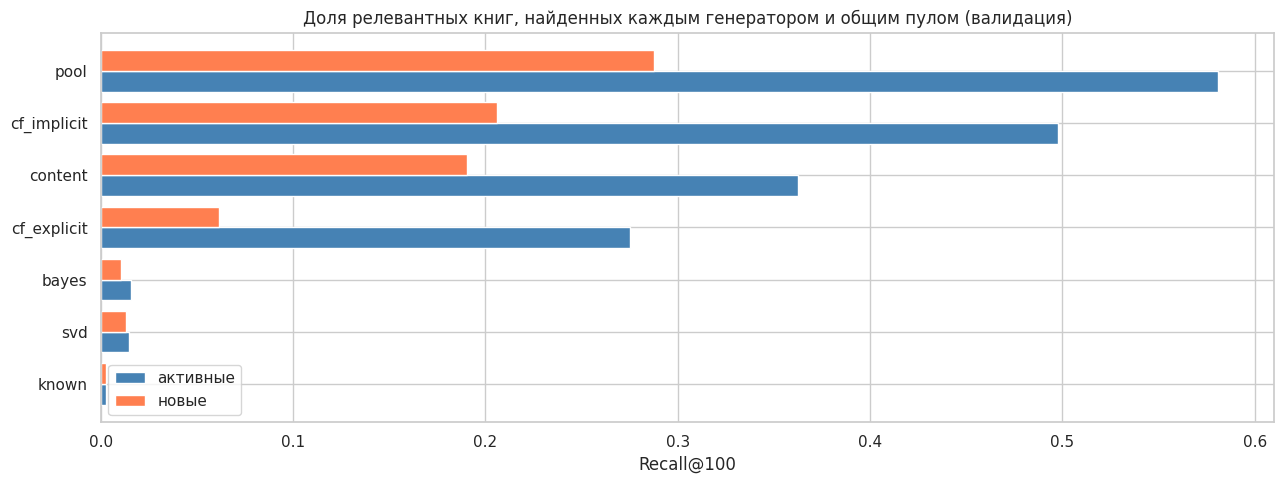

In [11]:
order = recall.sort_values('активные').index
y     = np.arange(len(order))

fig, ax = plt.subplots(figsize=(13, 5))
ax.barh(y - 0.2, recall.loc[order, 'активные'], height=0.4, color='steelblue', label='активные')
ax.barh(y + 0.2, recall.loc[order, 'новые'], height=0.4, color='coral', label='новые')
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.set_xlabel(f'Recall@{N_PER_MODEL}')
ax.set_title('Доля релевантных книг, найденных каждым генератором и общим пулом (валидация)')
ax.legend()
plt.tight_layout(); plt.show()

Общий пул находит 58,1% релевантных книг активного пользователя против 49,8% у лучшей отдельной модели, item-based CF на факте прочтения, и 28,7% против 20,6% у новых. Почти весь прирост даёт контентная модель (36,2% и 19,0% сама по себе): она находит книги, которых у CF нет. Запас над лучшей моделью есть, и это потолок для ранжирования на втором этапе.

SVD и обе популярные модели находят 0,2–1,6% релевантных книг, на уровне случайной выдачи (около 1% при 100 книгах из 10 000). Популярность по ratings_count находит 0,2–0,3%, то есть даже меньше случайной.

## 6. Признаки

Признаки считаются только по обучающей части. Признаки пользователя (число оценок, средняя, разброс, доля оценок не ниже 4) одинаковы для всех его кандидатов и в линейной сумме не меняют порядок книг внутри списка, поэтому они работают через сегментацию: от числа оценок зависит, какие веса применяются. Порядок меняют признаки книги и пары: популярность по Goodreads (log_ratings_count), байесовская средняя, разброс оценок, косинус к TF-IDF-профилю пользователя (content_cos), сумма и максимум item-based сходства с прочитанным (cf_sum, cf_max), пересечение жанров книги с жанрами прочитанного (genre_affinity). Признаки пары считаются для всех кандидатов пула, в том числе для книг, которые соответствующая модель в свой топ-100 не взяла: скор CF известен и для книги, найденной контентной моделью. Каждый признак переводится в перцентиль среди кандидатов пользователя.

In [12]:
user_feats = features.user_features(fit_t, idx)
user_feats.groupby(segment).describe().T.round(2)

active       new
n_ratings   count  36632.00  16792.00
            mean      15.14      2.32
            std       17.65      0.59
            min        4.00      1.00
            25%        4.00      2.00
            50%        8.00      2.00
            75%       18.00      3.00
            max      128.00      3.00
mean_rating count  36632.00  16792.00
            mean       3.87      3.90
            std        0.58      0.78
            min        1.00      1.00
            25%        3.50      3.50
            50%        3.86      4.00
            75%        4.25      4.50
            max        5.00      5.00
std_rating  count  36632.00  16792.00
            mean       0.72      0.44
            std        0.32      0.44
            min        0.00      0.00
            25%        0.50      0.00
            50%        0.73      0.47
            75%        0.90      0.50
            max        2.00      2.00
share_liked count  36632.00  16792.00
            mean       0.67      0.68
            std        0.26      0.36
            min        0.00      0.00
            25%        0.50      0.50
            50%        0.71      0.67
            75%        0.88      1.00
            max        1.00      1.00

In [13]:
coverage, by_genre = features.genre_coverage(fitted.genres)
print(f'Книг хотя бы с одним жанром: {coverage:.1%}')
fitted.book_feats.describe().T.round(2)

Книг хотя бы с одним жанром: 98.8%


,count,mean,std,min,25%,50%,75%,max
n_train,10000.0,59.37,6.72,4.00,55.00,59.00,64.00,86.00
std_rating,10000.0,0.92,0.13,0.39,0.83,0.92,1.01,1.67
bayes_mean,10000.0,3.86,0.16,2.92,3.76,3.87,3.96,4.38
log_ratings_count,10000.0,10.19,0.94,7.91,9.52,9.96,10.62,15.38
n_genres,10000.0,2.97,1.47,0.00,2.00,3.00,4.00,10.00


In [14]:
feat_cols  = list(fitted.generators) + list(pipeline.POOL_FEATURES)
separation = pool_val.groupby('hit')[feat_cols].mean().T
separation.columns = ['нерелевантные', 'релевантные']
separation['разница'] = separation['релевантные'] - separation['нерелевантные']
separation.sort_values('разница').round(3)

,нерелевантные,релевантные,разница
bayes_mean,0.501,0.395,-0.106
bayes,0.108,0.011,-0.097
log_ratings_count,0.501,0.405,-0.097
svd,0.108,0.012,-0.096
known,0.108,0.013,-0.095
std_rating,0.501,0.561,0.060
genre_affinity,0.500,0.731,0.230
cf_explicit,0.107,0.372,0.265
content,0.106,0.390,0.284
content_cos,0.500,0.806,0.306


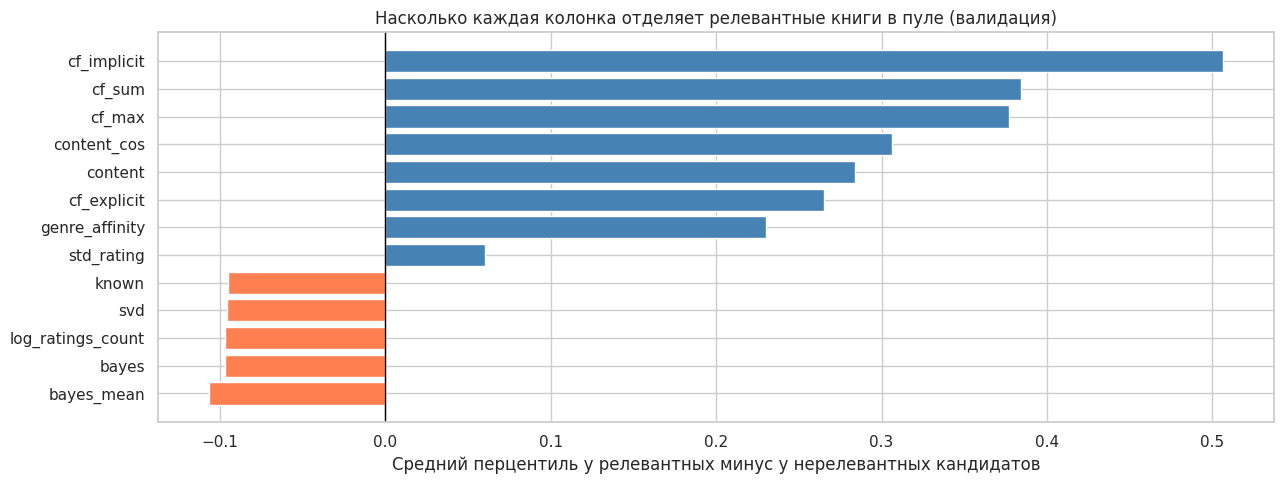

In [15]:
diff = separation['разница'].sort_values()

fig, ax = plt.subplots(figsize=(13, 5))
ax.barh(diff.index, diff.values, color=np.where(diff.values > 0, 'steelblue', 'coral'))
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('Средний перцентиль у релевантных минус у нерелевантных кандидатов')
ax.set_title('Насколько каждая колонка отделяет релевантные книги в пуле (валидация)')
plt.tight_layout(); plt.show()

Сильнее всего релевантные кандидаты отличаются по признакам item-based CF: у релевантных cf_sum и cf_max в среднем на 0,38 перцентиля выше, content_cos на 0,31, пересечение жанров на 0,23. Популярность и средняя оценка работают в обратную сторону: релевантные кандидаты в среднем менее известны (перцентиль log_ratings_count 0,41 против 0,50) и имеют более низкую сглаженную среднюю.

Вероятная причина в устройстве датасета. В ratings.csv у 62,5% книг ровно 100 оценок (раздел 5 ноутбука домашнего задания), поэтому известная книга попадает в историю пользователя не чаще нишевой, и популярность на Goodreads не предсказывает, что пользователь прочитает. Это предположение: проверить его без полного набора оценок Goodreads нельзя. Сильные признаки во многом повторяют то, что уже знает cf_implicit, поэтому большой прибавки от них ждать не стоит.

## 7. Отдельные модели на валидации

Чтобы получить выдачу одной модели, в пуле берётся вес 1 у её колонки и 0 у остальных. Её топ-10 совпадает с топ-10 по всему каталогу, потому что пул содержит топ-100 каждой модели целиком (это проверено на синтетических данных сравнением с metrics.evaluate из домашнего задания).

In [16]:
single = pd.DataFrame([{'модель': g, 'сегмент': SEGMENTS[s],
                        **hybrid.ranking_metrics(pool_val, hybrid.hybrid_score(pool_val, {g: 1.0}), rel_val, K, users=u)}
                       for s, u in seg_users.items() for g in fitted.generators])
single.pivot(index='модель', columns='сегмент', values=f'nDCG@{K}').sort_values('активные', ascending=False).round(4)

сегмент,активные,новые
модель,,
cf_implicit,0.1732,0.0643
cf_explicit,0.1181,0.0252
content,0.0937,0.0498
svd,0.0012,0.0010
bayes,0.0011,0.0004
known,0.0005,0.0003


Порядок моделей на валидации тот же, что в домашнем задании. Item-based CF на факте прочтения лучший в обоих сегментах: 0,1732 у активных и 0,0643 у новых. Второе место у активных занимает item-based CF на оценках, у новых контентная модель. У новых пользователей качество моделей ниже в 1,9–4,7 раза: меньше всего проседает контентная модель, сильнее всего item-based CF на оценках. SVD и популярные модели остаются на уровне случайной выдачи.

## 8. Подбор весов гибрида

Веса подбираются координатным подъёмом по nDCG@10: по очереди для каждой колонки перебираются значения из сетки [-0,5; 0; 0,05; 0,1; 0,25; 0,5; 1; 2] при остальных фиксированных, изменение принимается, если nDCG растёт, проход повторяется дважды. Отрицательный вес разрешён: колонка может штрафовать кандидата. Стартовая точка: вес 1 у item-based CF на факте прочтения, лучшей модели домашнего задания, остальные 0. Подбор идёт отдельно для новых и активных пользователей и в два этапа: сначала только ранги моделей, затем к подобранным весам моделей добавляются признаки с нулевым стартовым весом и подбор продолжается. Второй вариант стартует с решения первого, поэтому на пользователях подбора он не может оказаться хуже, а разница между ними показывает вклад признаков. При общем старте жадный поиск по большему числу колонок мог застрять в худшем локальном максимуме. Для ускорения веса активного сегмента подбираются на случайных 8000 пользователях.

In [17]:
init_models = {g: float(g == 'cf_implicit') for g in fitted.generators}
rng         = np.random.default_rng(SEED)
tune_users  = {'new': seg_users['new'],
               'active': rng.choice(seg_users['active'], min(N_TUNE, len(seg_users['active'])), replace=False)}

weights, tuning = {}, []
for s, u in tune_users.items():
    start = hybrid.ranking_metrics(pool_val, hybrid.hybrid_score(pool_val, init_models), rel_val, K, users=u)[f'nDCG@{K}']
    for variant in ('модели', 'модели + признаки'):
        init = init_models if variant == 'модели' else {**weights[('модели', s)], **{f: 0.0 for f in pipeline.POOL_FEATURES}}
        w, best, hist = hybrid.tune_weights(pool_val, rel_val, init, GRID, k=K, users=u)
        weights[(variant, s)] = w
        tuning.append({'вариант': variant, 'сегмент': SEGMENTS[s], 'cf_implicit': start,
                       'гибрид': best, 'шагов': len(hist) - 1})

pd.DataFrame(tuning).round(4)

,вариант,сегмент,cf_implicit,гибрид,шагов
0,модели,новые,0.0643,0.0671,8
1,модели + признаки,новые,0.0643,0.0682,7
2,модели,активные,0.1716,0.1748,2
3,модели + признаки,активные,0.1716,0.1754,4


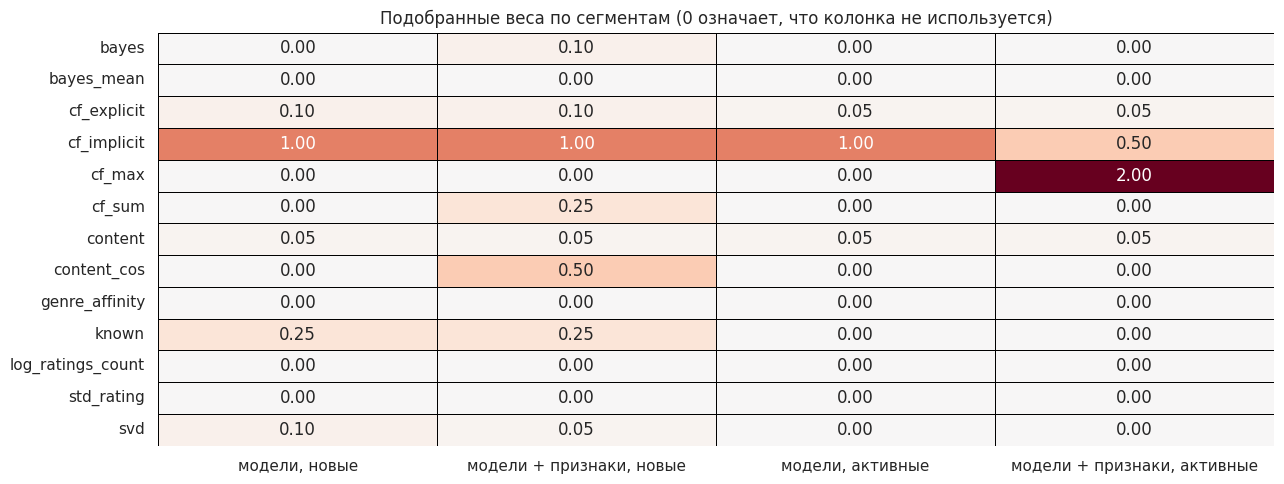

In [18]:
weight_table = pd.DataFrame({f'{v}, {SEGMENTS[s]}': pd.Series(w) for (v, s), w in weights.items()}).fillna(0)

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(weight_table, annot=True, fmt='.2f', cmap='RdBu_r', center=0, cbar=False, linewidths=0.5, linecolor='black', ax=ax)
ax.set_title('Подобранные веса по сегментам (0 означает, что колонка не используется)')
plt.tight_layout(); plt.show()

Сначала веса подбирались на сетке [-0,5; 0; 0,25; 0,5; 1; 2]. У активных пользователей подбор тогда не сдвинулся со стартовой точки, у новых дал 0,0667 против 0,0643. Чтобы отделить грубость сетки от предела самой линейной суммы, перед повторным запуском был зафиксирован критерий: если с шагами 0,05 и 0,1 прирост у активных на валидации составит не меньше 1%, причина в сетке. Прирост составил 1,9% (0,1716 и 0,1748), с признаками 2,2% (0,1754), поэтому итоговая сетка мелкая. У новых гибрид даёт 0,0671 без признаков и 0,0682 с признаками (+4,4% и +6,1%). Все эти числа посчитаны на пользователях, на которых подбирались веса, поэтому они оптимистичны.

У активных пользователей почти весь вес остаётся у cf_implicit, остальные модели получают по 0,05. С признаками подбор переносит вес на cf_max (2 против 0,5 у cf_implicit): кандидат поднимается, если он очень похож хотя бы на одну прочитанную книгу. У новых заметный вес получают популярность по ratings_count (0,25), SVD и item-based CF на оценках, а с признаками ещё content_cos (0,5). Признаки популярности и средней оценки книги не используются ни в одном сегменте.

## 9. Разнообразие выдачи

Финальный топ-10 строится жадно методом MMR из 50 лучших кандидатов гибрида: на каждом шаге берётся книга с максимумом λ·скор − (1 − λ)·max сходства с уже выбранными, где сходство это коэффициент Жаккара между множествами жанров. При λ = 1 выдача совпадает с гибридом, с уменьшением λ в списке становится больше разных жанров. Разнообразие измеряется ILS, средним попарным сходством жанров внутри списка (меньше значит разнообразнее), и числом жанров в списке.

Правило выбора λ зафиксировано до запуска: берётся наименьшее λ, при котором nDCG@10 на валидации не ниже 98% от nDCG@10 без переранжирования.

In [19]:
w_best    = {s: weights[('модели + признаки', s)] for s in SEGMENTS}
score_val = hybrid.segment_score(pool_val, segment, w_best)
gr_count  = books.set_index('id').ratings_count.reindex(idx.books).to_numpy()

mmr_rows = []
for lam in LAMBDAS:
    s = hybrid.mmr_rerank(pool_val, score_val, fitted.genres, k=K, lam=lam)
    mmr_rows.append({'λ': lam, **hybrid.ranking_metrics(pool_val, s, rel_val, K),
                     **hybrid.list_properties(pool_val, s, fitted.genres, gr_count, len(idx.books), K)})
mmr_table = pd.DataFrame(mmr_rows)
mmr_table.round(4)

,λ,Precision@10,Recall@10,nDCG@10,ILS (жанры),жанров в списке,покрытие каталога,медиана популярности
0,1.0,0.0589,0.2198,0.1636,0.5506,6.6822,0.9420,20639.0
1,0.9,0.0591,0.2209,0.1641,0.5217,7.0684,0.9453,20559.0
2,0.8,0.0591,0.2205,0.1626,0.4854,7.5259,0.9468,20511.0
3,0.7,0.0584,0.2169,0.1591,0.4420,8.0404,0.9500,20432.0
4,0.6,0.0569,0.2110,0.1542,0.3907,8.6410,0.9533,20345.0
5,0.5,0.0538,0.1987,0.1469,0.3365,9.2634,0.9574,20260.0


Выбранное λ: 0.8


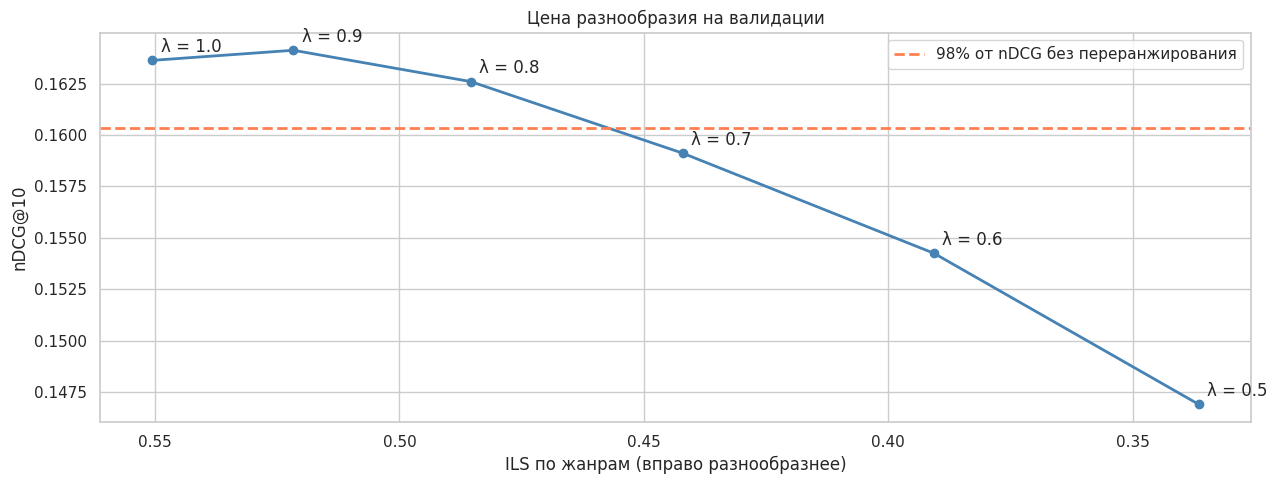

In [20]:
base   = mmr_table.loc[mmr_table['λ'] == 1.0, f'nDCG@{K}'].iloc[0]
LAMBDA = mmr_table.loc[mmr_table[f'nDCG@{K}'] >= 0.98 * base, 'λ'].min()
print(f'Выбранное λ: {LAMBDA}')

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(mmr_table['ILS (жанры)'], mmr_table[f'nDCG@{K}'], color='steelblue', lw=2, marker='o')
for _, row in mmr_table.iterrows():
    ax.annotate(f"λ = {row['λ']}", (row['ILS (жанры)'], row[f'nDCG@{K}']), textcoords='offset points', xytext=(6, 6))
ax.axhline(0.98 * base, color='coral', lw=2, ls='--', label='98% от nDCG без переранжирования')
ax.invert_xaxis()
ax.set_xlabel('ILS по жанрам (вправо разнообразнее)')
ax.set_ylabel(f'nDCG@{K}')
ax.set_title('Цена разнообразия на валидации')
ax.legend()
plt.tight_layout(); plt.show()

Цена разнообразия на валидации небольшая. При λ = 0,8 nDCG@10 снижается на 0,6% (0,1636 и 0,1626), ILS падает с 0,551 до 0,485, а жанров в списке становится 7,5 вместо 6,7. Дальше nDCG падает быстрее: при λ = 0,7 на 2,8%, при λ = 0,5 на 10,2%. По правилу, заданному до запуска, выбрано λ = 0,8.

## 10. Итоговая проверка на тестовой выборке

Модели переобучаются на объединении обучающей и валидационной частей. Новые пользователи моделируются тем же способом, но среди пользователей теста. Веса и λ берутся с валидации без изменений. Сравниваются шесть отдельных моделей и три варианта гибрида: только ранги моделей, ранги моделей с признаками и последний вариант с переранжированием MMR.

In [21]:
del pool_val

rel_test               = metrics.relevance_matrix(test, idx, THRESHOLD)
train_t, new_test_users = pipeline.simulate_new_users(pd.concat([fit, val], ignore_index=True), rel_test, idx,
                                                      n_users=N_NEW, seed=SEED)
fitted_t   = pipeline.fit_models(train_t, books, book_tags, idx)
test_users = np.flatnonzero(np.diff(rel_test.indptr))
pool_test  = pipeline.scored_pool(fitted_t, test_users, rel_test, n_per_model=N_PER_MODEL)
segment_t  = hybrid.segment_of(fitted_t.n_ratings)
seg_test   = {s: test_users[segment_t[test_users] == s] for s in SEGMENTS}

print(f'Пользователей теста: {len(test_users):,} (новых {len(seg_test["new"]):,}, активных {len(seg_test["active"]):,})')
pd.DataFrame({SEGMENTS[s]: hybrid.pool_recall(pool_test[pool_test.user.isin(u)], rel_test)
              for s, u in seg_test.items()}).round(3)

Пользователей теста: 30,542 (новых 3,000, активных 27,542)


,новые,активные
pool,0.302,0.609


In [22]:
systems = {g: hybrid.hybrid_score(pool_test, {g: 1.0}) for g in fitted_t.generators}
systems['гибрид: модели']            = hybrid.segment_score(pool_test, segment_t, {s: weights[('модели', s)] for s in SEGMENTS})
systems['гибрид: модели + признаки'] = hybrid.segment_score(pool_test, segment_t, w_best)
systems['гибрид + MMR']              = hybrid.mmr_rerank(pool_test, systems['гибрид: модели + признаки'], fitted_t.genres, k=K, lam=LAMBDA)

final = []
for name, score in systems.items():
    row = {'система': name}
    for s, u in (('все', test_users), *((SEGMENTS[s], u) for s, u in seg_test.items())):
        row[f'nDCG@{K}, {s}'] = hybrid.ranking_metrics(pool_test, score, rel_test, K, users=u)[f'nDCG@{K}']
    m = hybrid.ranking_metrics(pool_test, score, rel_test, K)
    row.update({f'Precision@{K}': m[f'Precision@{K}'], f'Recall@{K}': m[f'Recall@{K}'],
                **hybrid.list_properties(pool_test, score, fitted_t.genres, gr_count, len(idx.books), K)})
    final.append(row)
final = pd.DataFrame(final)
final.round(4)

,система,"nDCG@10, все","nDCG@10, новые","nDCG@10, активные",Precision@10,Recall@10,ILS (жанры),жанров в списке,покрытие каталога,медиана популярности
0,cf_implicit,0.2017,0.0711,0.2159,0.0759,0.2418,0.5590,6.5351,0.9470,20177.0
1,cf_explicit,0.1322,0.0269,0.1436,0.0522,0.1482,0.4466,7.9936,0.9902,20812.0
2,content,0.1048,0.0543,0.1103,0.0399,0.1397,0.6168,6.2553,0.9140,25001.0
3,svd,0.0010,0.0011,0.0010,0.0006,0.0015,0.3464,9.6833,0.0110,17179.0
4,known,0.0008,0.0006,0.0008,0.0007,0.0003,0.2839,11.0010,0.0030,2346404.0
5,bayes,0.0009,0.0006,0.0009,0.0005,0.0015,0.2420,11.9972,0.0016,14597.0
6,гибрид: модели,0.2021,0.0728,0.2161,0.0772,0.2454,0.5629,6.4961,0.9463,20313.0
7,гибрид: модели + признаки,0.2018,0.0737,0.2157,0.0777,0.2443,0.5525,6.6213,0.9417,20377.0
8,гибрид + MMR,0.2026,0.0729,0.2167,0.0787,0.2475,0.4876,7.4481,0.9480,20198.0


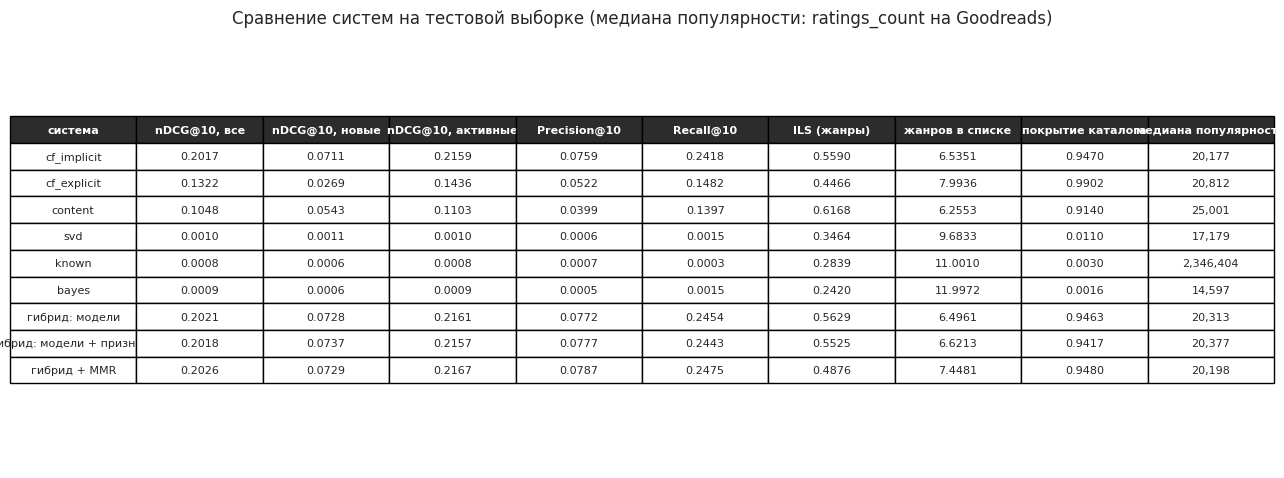

In [23]:
table = final.copy()
for col in table.columns[1:]:
    table[col] = table[col].map(lambda v: f'{v:,.0f}' if col == 'медиана популярности' else f'{v:.4f}')
show_table(table, 'Сравнение систем на тестовой выборке (медиана популярности: ratings_count на Goodreads)', fontsize=8); plt.show()

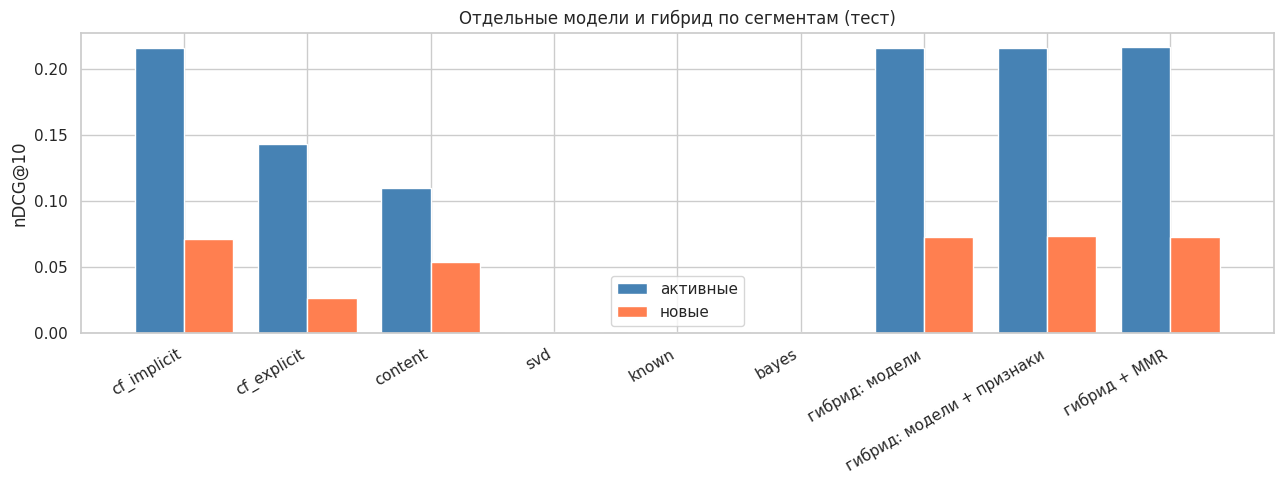

In [24]:
plot_df = final.set_index('система')[[f'nDCG@{K}, новые', f'nDCG@{K}, активные']]
x       = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - 0.2, plot_df.iloc[:, 1], width=0.4, color='steelblue', label='активные')
ax.bar(x + 0.2, plot_df.iloc[:, 0], width=0.4, color='coral', label='новые')
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=30, ha='right')
ax.set_ylabel(f'nDCG@{K}')
ax.set_title('Отдельные модели и гибрид по сегментам (тест)')
ax.legend()
plt.tight_layout(); plt.show()

На тесте гибрид обгоняет cf_implicit только у новых пользователей: 0,0737 против 0,0711 в варианте с признаками (+3,7%). У активных все три варианта гибрида остаются на уровне cf_implicit: 0,2161, 0,2157 и 0,2167 против 0,2159. Прирост в 1,9–2,2%, полученный на валидации, на тест не перенёсся.

MMR добавляет разнообразие почти бесплатно. По всем пользователям nDCG@10 0,2026 против 0,2018 у гибрида без переранжирования, Recall@10 0,2475 против 0,2443, ILS 0,488 против 0,553, жанров в списке 7,4 против 6,6. Покрытие каталога у всех персональных систем около 95%, у популярных моделей меньше 1%: они выдают всем одни и те же книги.

Внутри активного сегмента качество сравнивается по группам активности, как в домашнем задании: гибрид может выигрывать у пользователей с короткой историей и не давать ничего тем, у кого историй много.

In [25]:
groups   = pd.cut(fitted_t.n_ratings[seg_test['active']], bins=[3, 10, 30, 100, 1000], labels=['4–10', '11–30', '31–100', '>100'])
by_group = pd.DataFrame({name: [hybrid.ranking_metrics(pool_test, systems[name], rel_test, K,
                                                       users=seg_test['active'][groups == g])[f'nDCG@{K}']
                                for g in groups.categories]
                         for name in ('cf_implicit', 'гибрид: модели', 'гибрид: модели + признаки')},
                        index=groups.categories)
by_group.insert(0, 'пользователей', pd.Series(groups).value_counts().reindex(groups.categories).values)
by_group.index.name = 'оценок в train'
by_group.round(4)

,пользователей,cf_implicit,гибрид: модели,гибрид: модели + признаки
оценок в train,,,,
4–10,10747,0.2093,0.2049,0.2034
11–30,10658,0.2127,0.2135,0.2124
31–100,5592,0.2294,0.2362,0.2389
>100,545,0.2709,0.2820,0.2852


Нулевой средний результат у активных пользователей складывается из эффектов разного знака. У пользователей с 31–100 и более чем 100 книгами в обучающей части гибрид с признаками лучше cf_implicit на 4,1% и 5,3%, у пользователей с 4–10 книгами хуже на 2,8%, в группе 11–30 разницы нет. Подобранные веса подходят тем, кто много читал: при длинной истории сумма сходств размыта, и сходство с самой похожей прочитанной книгой (cf_max) точнее. У пользователя с несколькими книгами это одно сходство случайно. Один набор весов на всех активных пользователей усредняет два разных правила.

Это наблюдение получено на тестовой выборке, поэтому подбирать по нему сегменты в этом ноутбуке нельзя: тест превратился бы в ещё одну валидацию. Проверить его должен нейросетевой ранжировщик (ноутбук 03), которому число оценок пользователя подаётся как признак: нелинейная модель может сама менять правило в зависимости от длины истории.

## 11. Выводы

Гибрид собран из шести генераторов кандидатов: item-based CF на факте прочтения и на оценках, контентной модели, SVD и двух популярных моделей. Их кандидаты объединяются в пул, скоры переводятся в ранги и складываются с весами, отдельными для новых и активных пользователей, затем выдача переранжируется по жанрам. Пул на тесте содержит 60,9% релевантных книг активного пользователя и 30,2% у нового. Это заметно больше, чем у лучшей модели в одиночку, но линейная сумма рангов этот запас почти не использует.

На тесте гибрид с признаками лучше item-based CF на факте прочтения у новых пользователей (nDCG@10 0,0737 против 0,0711) и не отличается от него у активных (0,2157 против 0,2159). Внутри активных он помогает тем, у кого больше 30 книг, и вредит тем, у кого 4–10. Причина различий в том, что одни и те же веса не подходят пользователям с короткой и длинной историей.

Сильные и слабые стороны методов. Item-based CF на факте прочтения остаётся основой: среди отдельных моделей он лучший в обоих сегментах, и в гибриде у него наибольший вес. Контентная модель слабее в ранжировании, зато находит книги, которых у CF нет, и даёт основную часть прироста пула. SVD обучен предсказывать оценку и на ранжировании бесполезен, как и в домашнем задании. Популярность на Goodbooks не помогает даже новым пользователям: популярные книги попадают в пул, но релевантными оказываются реже случайных, что, вероятно, связано с ограничением в 100 оценок на книгу при сборке датасета.

Рекомендации по выбору модели. Для пользователей с историей от 4 книг item-based CF на факте прочтения так же точен, как гибрид, и проще в поддержке. Для новых пользователей с 1–3 книгами гибрид с контентом и популярностью даёт прирост около 4%. Переранжирование MMR с λ = 0,8 стоит включать в обоих случаях: оно добавляет почти один жанр в каждый список без потери точности.

Расхождение валидации и теста имеет две вероятные причины. Первая: веса подбирались для моделей, обученных на 68% оценок, а на тесте применялись к моделям, обученным на 82%. С большей историей CF сильнее, и оптимальные веса сдвигаются. Вторая: разные группы активности хотят разных весов, и их соотношение в выборках, на которых подбирались веса, не совпадает с тестом. Оба объяснения не проверены.

Ограничения. Временных меток нет, поэтому разбиение случайное внутри пользователя и не имитирует будущее. Новые пользователи смоделированы обрезкой истории у активных, и их вкус может отличаться от вкуса настоящих новичков. Тестовая выборка открывалась дважды: в первом прогоне с грубой сеткой весов и во втором с мелкой. Решение о сетке принималось по критерию на валидации, заданному до второго запуска, но сам факт двух просмотров теста делает итоговые числа чуть оптимистичнее.